# Homework 2 — Variational Autoencoders

**Student ID:** 411221351  


I use the aligned CelebA face images stored on my local space. The notebook covers reconstruction with a two-dimensional latent space, comparisons of three β values, and excessive regularization. The experiments use a separate test set and save figures as PNG files.




## Setup

I first check that the notebook kernel is responding and then load the required libraries. The setup cells print progress so that I can see whether an import or CUDA initialization is taking time. I use fixed random seeds to make the experiments more reproducible.


In [1]:
# This cell should finish immediately if the selected Jupyter kernel is working.
from pathlib import Path
import sys
import time
print('Kernel is working.', flush=True)
print('Python:', sys.version.split()[0], flush=True)
print('Working directory:', Path.cwd(), flush=True)


Kernel is working.
Python: 3.14.5
Working directory: d:\downloads\Gen AI\homework2


In [ ]:

print('Importing PyTorch...', flush=True)
start_import = time.perf_counter()
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
print(f'PyTorch imported in {time.perf_counter()-start_import:.1f} seconds.', flush=True)

print('Checking CUDA...', flush=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| Device:', DEVICE, flush=True)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0), flush=True)
else:
    print('CUDA is unavailable in this kernel; training will use the CPU.', flush=True)


Importing PyTorch...
PyTorch imported in 17.9 seconds.
Checking CUDA...
PyTorch: 2.14.1+cu130 | Device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


In [3]:
print('Importing image and notebook libraries...', flush=True)
import random
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms
from torchvision.utils import make_grid

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if DEVICE.type == 'cuda':
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

FIG_DIR = Path('hw2_figures')
MODEL_DIR = Path('hw2_models')
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
print('Setup complete. Figures:', FIG_DIR.resolve(), flush=True)
print('Model checkpoints:', MODEL_DIR.resolve(), flush=True)


Importing image and notebook libraries...
Setup complete. Figures: D:\downloads\Gen AI\homework2\hw2_figures
Model checkpoints: D:\downloads\Gen AI\homework2\hw2_models


## CelebA dataset and preprocessing

I use the aligned CelebA images already extracted on my computer. Each RGB image is resized to 64×64 pixels and converted into a tensor between 0 and 1. I checked earlier that the folder contains all 202,599 numbered JPG images. To avoid scanning that large folder every time, this notebook constructs the filenames directly and checks sample files before continuing.

If the official `list_eval_partition.txt` is present, I use it. Otherwise I follow the documented CelebA ordered partition: 162,770 training images, 19,867 validation images, and 19,962 test images. Training and test images remain separate.


In [ ]:
print('Checking local CelebA folder...', flush=True)
IMAGE_DIR = Path(r'D:\downloads\Gen AI\homework2\img_align_celeba\img_align_celeba')
if not (IMAGE_DIR / '000001.jpg').is_file():
    candidates = [
        IMAGE_DIR.parent,
        IMAGE_DIR.parent / 'img_align_celeba',
        IMAGE_DIR / 'img_align_celeba',
        Path.cwd() / 'img_align_celeba',
        Path.cwd() / 'img_align_celeba' / 'img_align_celeba',
    ]
    IMAGE_DIR = next((p for p in candidates if (p / '000001.jpg').is_file()), IMAGE_DIR)

probes = ['000001.jpg', '101300.jpg', '202599.jpg']
if not IMAGE_DIR.is_dir() or any(not (IMAGE_DIR / f).is_file() for f in probes):
    raise FileNotFoundError(
        f'Could not find the extracted CelebA images at {IMAGE_DIR}. '
        'Check IMAGE_DIR above; the inner folder must contain 000001.jpg to 202599.jpg.')
print('Found:', IMAGE_DIR, flush=True)


all_paths = [IMAGE_DIR / f'{i:06d}.jpg' for i in range(1, 202600)]
partition_candidates = [
    IMAGE_DIR / 'list_eval_partition.txt',
    IMAGE_DIR.parent / 'list_eval_partition.txt',
    IMAGE_DIR.parent.parent / 'list_eval_partition.txt',
]
partition_file = next((p for p in partition_candidates if p.is_file()), None)

if partition_file is not None:
    print('Reading official partition file...', flush=True)
    mapping = {}
    with partition_file.open(encoding='utf-8') as file:
        for line in file:
            parts = line.strip().split()
            if len(parts) == 2:
                mapping[parts[0]] = int(parts[1])
    if len(mapping) != len(all_paths):
        raise ValueError('The partition file does not cover all images.')
    train_paths = [p for p in all_paths if mapping[p.name] == 0]
    val_paths = [p for p in all_paths if mapping[p.name] == 1]
    test_paths = [p for p in all_paths if mapping[p.name] == 2]
    print('Official split file:', partition_file, flush=True)
else:
    train_paths = all_paths[:162770]
    val_paths = all_paths[162770:182637]
    test_paths = all_paths[182637:]
    print('Partition file not found; using standard ordered CelebA split.', flush=True)

assert (len(train_paths), len(val_paths), len(test_paths)) == (162770, 19867, 19962)
print('Train / validation / test:', len(train_paths), len(val_paths), len(test_paths), flush=True)

IMAGE_SIZE = 64
BATCH_SIZE = 96
NUM_WORKERS = 0  # Safe default for Windows VS Code Jupyter.
EPOCHS_2D = 5
EPOCHS_BETA = 6
EPOCHS_STRONG = 5
LEARNING_RATE = 2e-4
RETRAIN = False

# True runs a brief diagnostic only; keep False for the actual submission.
SMOKE_TEST = False
if SMOKE_TEST:
    train_paths = train_paths[:512]
    val_paths = val_paths[:128]
    test_paths = test_paths[:256]
    EPOCHS_2D = EPOCHS_BETA = EPOCHS_STRONG = 1
    print('SMOKE TEST ONLY: not suitable for submission.', flush=True)

preprocess = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])

class CelebAImages(Dataset):
    def __init__(self, paths, transform):
        self.paths, self.transform = paths, transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            return self.transform(image.convert('RGB'))

trainset = CelebAImages(train_paths, preprocess)
valset = CelebAImages(val_paths, preprocess)
testset = CelebAImages(test_paths, preprocess)
train_gen = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=DEVICE.type=='cuda',
                          generator=train_gen)
val_loader = DataLoader(valset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=DEVICE.type=='cuda')
test_loader = DataLoader(testset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=DEVICE.type=='cuda')
print('Data loaders are ready. No images have been downloaded.', flush=True)


Checking local CelebA folder (no download)...
Found: D:\downloads\Gen AI\homework2\img_align_celeba\img_align_celeba
Partition file not found; using standard ordered CelebA split.
Train / validation / test: 162770 19867 19962
Data loaders are ready. No images have been downloaded.


Preparing the first 144 test images for the comparison figures...


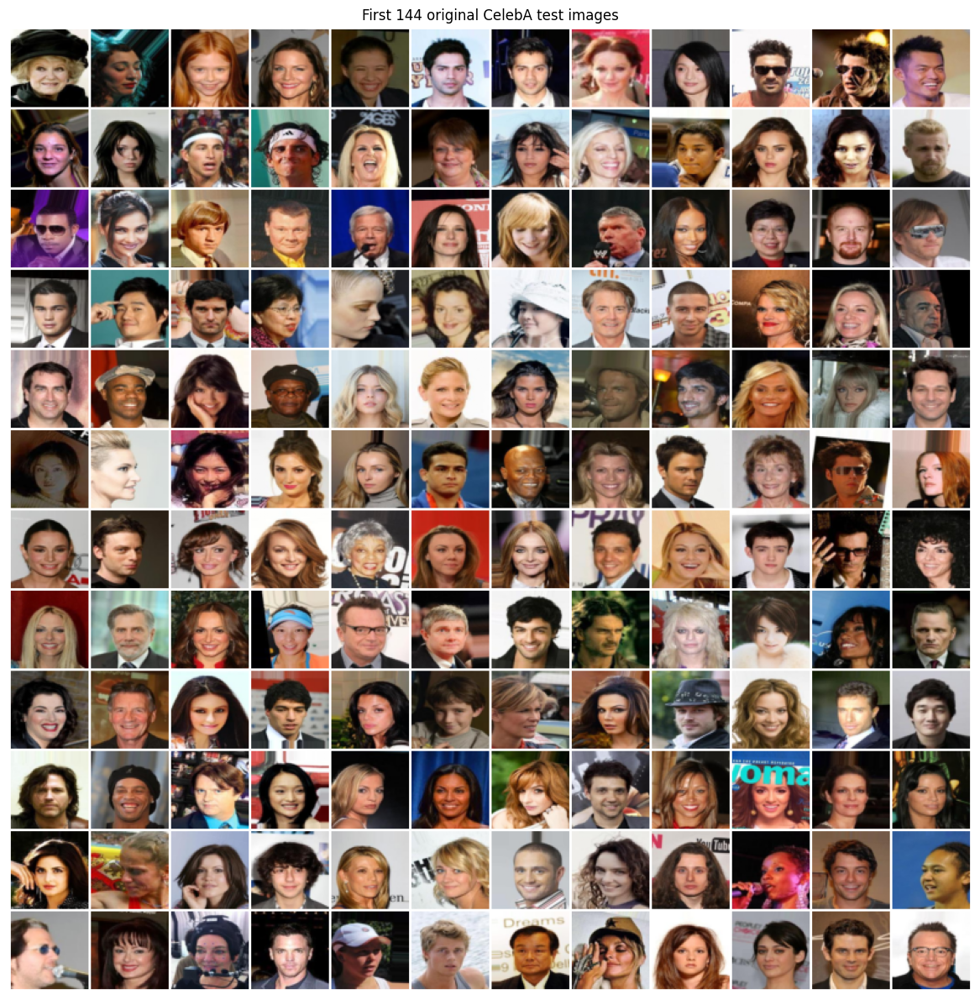

Saved: hw2_figures\original_12x12.png


In [ ]:

print('Preparing the first 144 test images for the comparison figures...', flush=True)
fixed_test = torch.stack([testset[i] for i in range(144)])
assert fixed_test.shape == (144, 3, 64, 64)

def save_grid(images, filename, title, columns=12):
    grid = make_grid(images.detach().float().cpu().clamp(0, 1),
                     nrow=columns, padding=2, pad_value=1)
    fig, ax = plt.subplots(figsize=(12, 12) if columns == 12 else (12, 3))
    ax.imshow(grid.permute(1, 2, 0).numpy())
    ax.set_title(title)
    ax.axis('off')
    fig.tight_layout()
    target = FIG_DIR / filename
    fig.savefig(target, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print('Saved:', target, flush=True)

save_grid(fixed_test, 'original_12x12.png', 'First 144 original CelebA test images')


## β-VAE model

The encoder reduces each 64×64 RGB image to a vector of means and a vector of log variances. Sampling uses the reparameterization trick, so gradients can still pass through the encoder. The decoder uses transposed convolution layers to turn the latent vector back into an RGB image.

I used the standard β-VAE loss:

\[
\mathcal{L} = \mathcal{L}_{\mathrm{reconstruction}} + \beta\,D_{\mathrm{KL}}\bigl(q_\phi(z\mid x)\;\|\;\mathcal{N}(0,I)\bigr).
\]

The reconstruction term is binary cross-entropy summed over image pixels, and KL divergence is summed over latent dimensions. The values are then averaged over the batch. The same definition is used for all β values, which makes the comparisons fair. This differs from applying β to reconstruction loss: for this assignment, increasing β must increase the pressure toward the standard normal prior.

In [6]:
class Encoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 4, stride=2, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, 4, stride=2, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(64, 128, 4, stride=2, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(128, 256, 4, stride=2, padding=1), nn.ReLU(inplace=True),
        )
        self.fc_mean = nn.Linear(256 * 4 * 4, latent_dim)
        self.fc_log_var = nn.Linear(256 * 4 * 4, latent_dim)

    def forward(self, image):
        h = self.features(image).flatten(1)
        return self.fc_mean(h), self.fc_log_var(h)


class Decoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.fc = nn.Linear(latent_dim, 256 * 4 * 4)
        self.deconvs = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1), nn.ReLU(inplace=True),
            nn.ConvTranspose2d(32, 3, 4, stride=2, padding=1),
        )

    def forward(self, z):
        h = self.fc(z).view(-1, 256, 4, 4)
        return self.deconvs(h)  # Logits. Apply sigmoid for display.


class BetaVAE(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim)

    @staticmethod
    def reparameterize(mean, log_var):
        epsilon = torch.randn_like(mean)
        return mean + torch.exp(0.5 * log_var) * epsilon

    def forward(self, image, sample=True):
        mean, log_var = self.encoder(image)
        z = self.reparameterize(mean, log_var) if sample else mean
        logits = self.decoder(z)
        return logits, mean, log_var

    def reconstruct(self, images):
        logits, _, _ = self.forward(images, sample=False)
        return torch.sigmoid(logits)

    def generate(self, z):
        return torch.sigmoid(self.decoder(z))


def vae_loss(images, logits, mean, log_var, beta):
    recon = F.binary_cross_entropy_with_logits(logits, images, reduction='none')
    recon = recon.flatten(1).sum(1).mean()  # Summed per image, averaged per batch.
    kl = (-0.5 * (1 + log_var - mean.square() - log_var.exp())).sum(1).mean()
    total = recon + beta * kl
    return total, recon, kl

# Confirm the encoder and decoder use the expected tensor sizes.
with torch.no_grad():
    dummy = torch.rand(2, 3, 64, 64).to(DEVICE)
    test_model = BetaVAE(latent_dim=2).to(DEVICE)
    logits, mean, log_var = test_model(dummy)
    assert logits.shape == dummy.shape
    assert mean.shape == log_var.shape == (2, 2)
    print('Model output shape:', tuple(logits.shape))
del test_model, dummy, logits, mean, log_var
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

Model output shape: (2, 3, 64, 64)


## Training and evaluation functions

I use the same optimizer, batch size, and preprocessing for the β comparison. The reconstruction and KL losses are reported separately, along with pixel MSE. The training cells print progress after the first batch and at regular intervals, which helps distinguish slow image loading from a frozen kernel. Training on the full CelebA dataset is computationally expensive even when CUDA is enabled.


In [7]:
def one_epoch(model, loader, beta, optimizer=None, phase="evaluation"):
    print(f"  {phase}: {len(loader)} batches", flush=True)
    training = optimizer is not None
    model.train(training)
    totals = np.zeros(4, dtype=np.float64)
    seen = 0
    for batch_index, images in enumerate(loader, 1):
        images = images.to(DEVICE, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits, mean, log_var = model(images, sample=training)
            total, recon, kl = vae_loss(images, logits, mean, log_var, beta)
            if training:
                total.backward()
                optimizer.step()
        bs = images.shape[0]
        totals[:3] += np.array([total.item(), recon.item(), kl.item()]) * bs
        # Pixel MSE for monitoring; deterministic mean-code reconstruction at evaluation.
        comparison = torch.sigmoid(logits.detach())
        totals[3] += F.mse_loss(comparison, images, reduction='mean').item() * bs
        seen += bs
        if batch_index == 1 or batch_index % 200 == 0 or batch_index == len(loader):
            print(f'  {phase}: batch {batch_index}/{len(loader)} | '
                  f'images {seen:,} | loss {total.item():.1f}', flush=True)
    return dict(zip(['loss', 'reconstruction', 'kl', 'pixel_mse'],
                    (totals / seen).tolist()))


def fit_or_load(latent_dim, beta, epochs, tag):
    path = MODEL_DIR / f'{tag}_z{latent_dim}_beta{beta:g}_epochs{epochs}.pt'
    model = BetaVAE(latent_dim).to(DEVICE)
    if path.exists() and not RETRAIN:
        state = torch.load(path, map_location=DEVICE, weights_only=True)
        if (state['latent_dim'], state['beta'], state['epochs']) != (latent_dim, float(beta), epochs):
            raise ValueError('Checkpoint settings do not match this experiment.')
        model.load_state_dict(state['model_state'])
        model.eval()
        print('Loaded saved model:', path)
        return model, state['history']

    print(f'Starting {tag}: latent={latent_dim}, beta={beta:g}, '
          f'epochs={epochs}, train images={len(trainset):,}', flush=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = []
    start = time.perf_counter()
    for epoch in range(epochs):
        print(f'Epoch {epoch+1}/{epochs}', flush=True)
        train_stats = one_epoch(model, train_loader, beta, optimizer=optimizer, phase='train')
        val_stats = one_epoch(model, val_loader, beta, optimizer=None, phase='validation')
        history.append({'epoch': epoch + 1, 'train': train_stats, 'validation': val_stats})
        print(f'{tag} β={beta:g} z={latent_dim} '
              f'epoch {epoch+1}/{epochs} | '
              f'train {train_stats["loss"]:.1f} | '
              f'val {val_stats["loss"]:.1f} | '
              f'val recon {val_stats["reconstruction"]:.1f} | '
              f'val KL {val_stats["kl"]:.2f} | '
              f'elapsed {(time.perf_counter()-start)/60:.1f} min', flush=True)
    torch.save({'latent_dim': latent_dim, 'beta': float(beta),
                'epochs': epochs, 'model_state': model.state_dict(),
                'history': history}, path)
    print('Model saved:', path)
    model.eval()
    return model, history


def test_metrics(model, beta, max_batches=None):
    model.eval()
    # Evaluate on the complete test set by default.
    return one_epoch(model, test_loader, beta, optimizer=None, phase="test")


def plot_history(histories, filename):
    fig, axs = plt.subplots(1, 3, figsize=(15, 4))
    for label, hist in histories.items():
        epochs = [h['epoch'] for h in hist]
        for a, key, heading in zip(axs,
                                   ['reconstruction', 'kl', 'pixel_mse'],
                                   ['Reconstruction BCE', 'KL divergence', 'Pixel MSE']):
            a.plot(epochs, [h['validation'][key] for h in hist], label=label)
            a.set_xlabel('Epoch')
            a.set_title(heading)
            a.grid(alpha=.2)
    for a in axs:
        a.legend(fontsize=8)
    fig.tight_layout()
    dest = FIG_DIR / filename
    fig.savefig(dest, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print('Saved:', dest)


@torch.no_grad()
def reconstruct_first_ten(model):
    model.eval()
    images = fixed_test[:10].to(DEVICE)
    return model.reconstruct(images).cpu()


def save_reconstruction_comparison(original, reconstructions, labels, filename):
    # Each row holds the same 10 test images or their reconstructions.
    rows = [original[:10]] + [r[:10] for r in reconstructions]
    fig, axes = plt.subplots(len(rows), 10, figsize=(15, 1.85 * len(rows)))
    for i, row in enumerate(rows):
        for j in range(10):
            ax = axes[i, j]
            ax.imshow(row[j].permute(1, 2, 0).clamp(0, 1).numpy())
            ax.axis('off')
        axes[i, 0].text(-0.08, 0.5, (['Original'] + labels)[i],
                        transform=axes[i, 0].transAxes, rotation=90,
                        va='center', ha='right', fontsize=10)
    fig.tight_layout()
    dest = FIG_DIR / filename
    fig.savefig(dest, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print('Saved:', dest)


@torch.no_grad()
def decode_fixed_samples(model, latent_dim, n=144, seed=2026):
    model.eval()
    generator = torch.Generator().manual_seed(seed)
    z = torch.randn(n, latent_dim, generator=generator).to(DEVICE)
    return model.generate(z).cpu()

## Question 1(a) — Reconstruction with a two-dimensional latent space (30 points)

For this experiment I used a latent space with two dimensions and β = 1. The image passes through the encoder and is represented by only two numbers before being reconstructed. The figure below compares the **first ten test images** against their reconstructions. I use the encoder means during reconstruction so that the comparison does not change randomly each time it is plotted.

Loaded saved model: hw2_models\task_a_z2_beta1_epochs5.pt


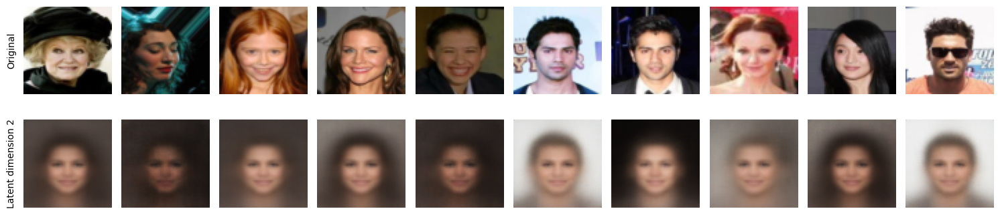

Saved: hw2_figures\a_first_10_reconstructions.png
  test: 208 batches
  test: batch 1/208 | images 96 | loss 7051.6
  test: batch 200/208 | images 19,200 | loss 7019.3
  test: batch 208/208 | images 19,962 | loss 7184.5
Latent dimension 2 test results: {'loss': 7138.170054695719, 'reconstruction': 7130.564406014005, 'kl': 7.605665077488093, 'pixel_mse': 0.040689783362850326}


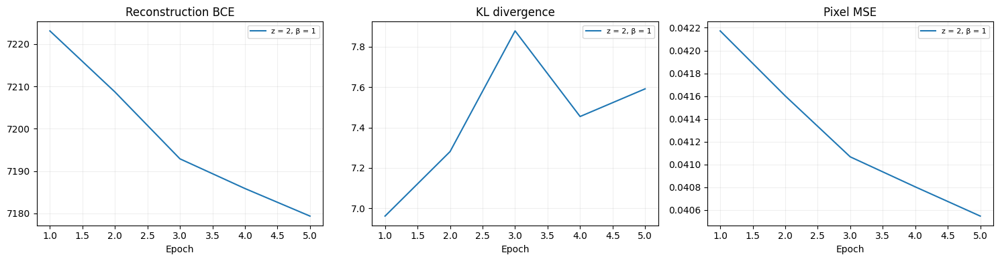

Saved: hw2_figures\a_training_curves.png


In [13]:
vae_2d, hist_2d = fit_or_load(latent_dim=2, beta=1.0,
                                   epochs=EPOCHS_2D, tag='task_a')
recon_2d = reconstruct_first_ten(vae_2d)
save_reconstruction_comparison(fixed_test, [recon_2d],
                               ['Latent dimension 2'], 'a_first_10_reconstructions.png')
metrics_2d = test_metrics(vae_2d, 1.0)
print('Latent dimension 2 test results:', metrics_2d)
plot_history({'z = 2, β = 1': hist_2d}, 'a_training_curves.png')

### Analysis — Question 1(a)

The reconstruction results show that a latent space of only two dimensions is too small to preserve much of the detail in the face images. Looking at the first ten test images, the reconstructed faces still have roughly the correct shape and colour, but they appear blurry. Some details, such as the eyes, hair and background, are not clearly reconstructed. I also noticed that some reconstructed faces look similar even though the original images are different.

The latent dimension affects reconstruction quality because it determines how much information the model can represent in its latent space. With only two dimensions, the model has limited capacity to preserve facial features. When comparing the reconstruction errors, the 2-dimensional model had a test pixel MSE of 0.040690, while the 32-dimensional model achieved 0.011527. This shows that increasing the latent dimension improved reconstruction quality in my experiment, although some blurriness remained.

## Question 1(b) — Compare β < 1, β = 1, and β > 1 (40 points)

I kept the latent dimension at **32** for this comparison. I tested β = **0.25**, β = **1**, and β = **8**. Lower β emphasizes matching the original image; higher β increases the cost of keeping information far from the standard normal prior. To make the visual comparison consistent, each model receives latent vectors generated using the same random seed. The first 144 test originals were saved above as a 12×12 grid.

Besides the required 12×12 grids of decoded images, I also include a two-dimensional latent traversal for each trained model. For each traversal, I change the two latent coordinates with the largest variation across encoded validation images while keeping the other coordinates at their average values. This helps show whether a change in one latent coordinate leads to a noticeable, consistent change in the generated face.

Starting task_b: latent=32, beta=0.25, epochs=6, train images=162,770
Epoch 1/6
  train: 1696 batches
  train: batch 1/1696 | images 96 | loss 8589.9
  train: batch 200/1696 | images 19,200 | loss 6787.9
  train: batch 400/1696 | images 38,400 | loss 6597.1
  train: batch 600/1696 | images 57,600 | loss 6623.0
  train: batch 800/1696 | images 76,800 | loss 6304.1
  train: batch 1000/1696 | images 96,000 | loss 6364.0
  train: batch 1200/1696 | images 115,200 | loss 6363.3
  train: batch 1400/1696 | images 134,400 | loss 6354.2
  train: batch 1600/1696 | images 153,600 | loss 6163.3
  train: batch 1696/1696 | images 162,770 | loss 6517.5
  validation: 207 batches
  validation: batch 1/207 | images 96 | loss 6428.4
  validation: batch 200/207 | images 19,200 | loss 6483.7
  validation: batch 207/207 | images 19,867 | loss 6570.8
task_b β=0.25 z=32 epoch 1/6 | train 6623.8 | val 6389.9 | val recon 6365.0 | val KL 99.76 | elapsed 2.0 min
Epoch 2/6
  train: 1696 batches
  train: batch 1/169

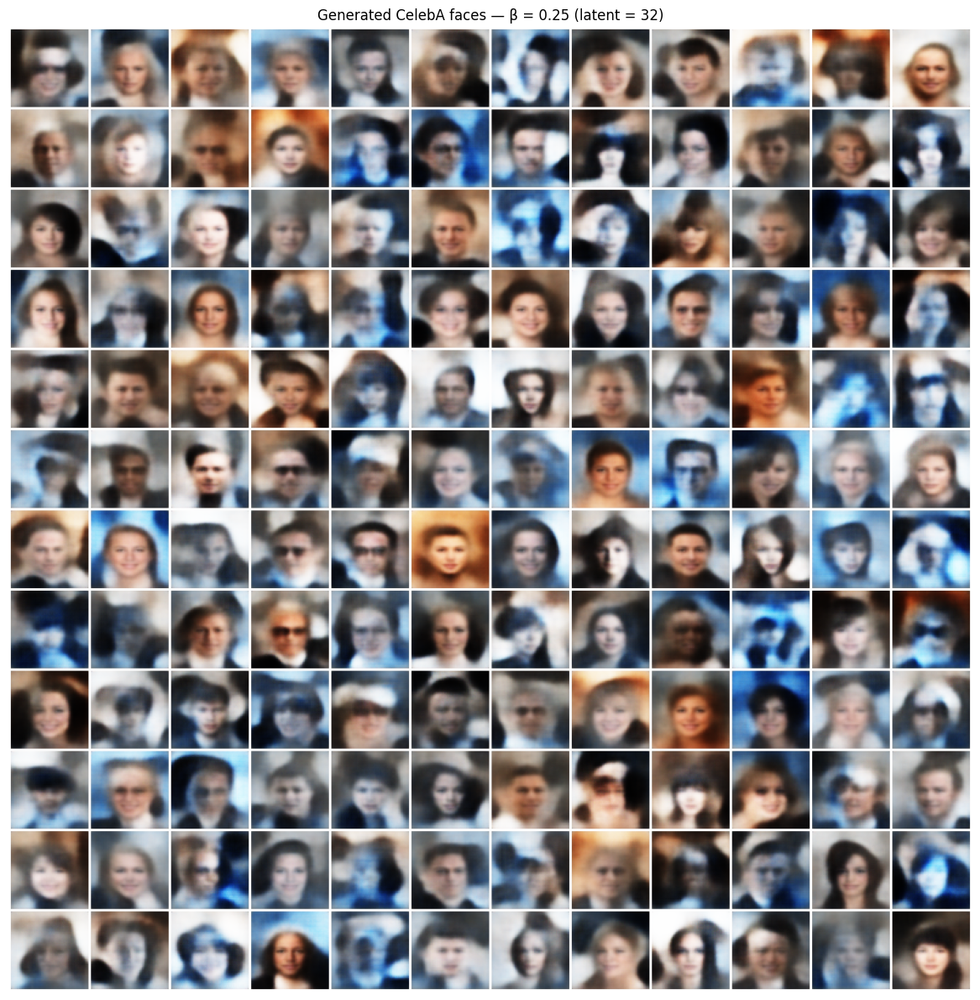

Saved: hw2_figures\b_beta_0p25_decoded_12x12.png
Starting task_b: latent=32, beta=1, epochs=6, train images=162,770
Epoch 1/6
  train: 1696 batches
  train: batch 1/1696 | images 96 | loss 8540.0
  train: batch 200/1696 | images 19,200 | loss 6933.0
  train: batch 400/1696 | images 38,400 | loss 6737.3
  train: batch 600/1696 | images 57,600 | loss 6669.2
  train: batch 800/1696 | images 76,800 | loss 6562.5
  train: batch 1000/1696 | images 96,000 | loss 6600.1
  train: batch 1200/1696 | images 115,200 | loss 6474.7
  train: batch 1400/1696 | images 134,400 | loss 6613.3
  train: batch 1600/1696 | images 153,600 | loss 6246.7
  train: batch 1696/1696 | images 162,770 | loss 6564.3
  validation: 207 batches
  validation: batch 1/207 | images 96 | loss 6473.0
  validation: batch 200/207 | images 19,200 | loss 6521.4
  validation: batch 207/207 | images 19,867 | loss 6608.4
task_b β=1 z=32 epoch 1/6 | train 6654.1 | val 6426.8 | val recon 6357.5 | val KL 69.26 | elapsed 2.0 min
Epoch 2/6

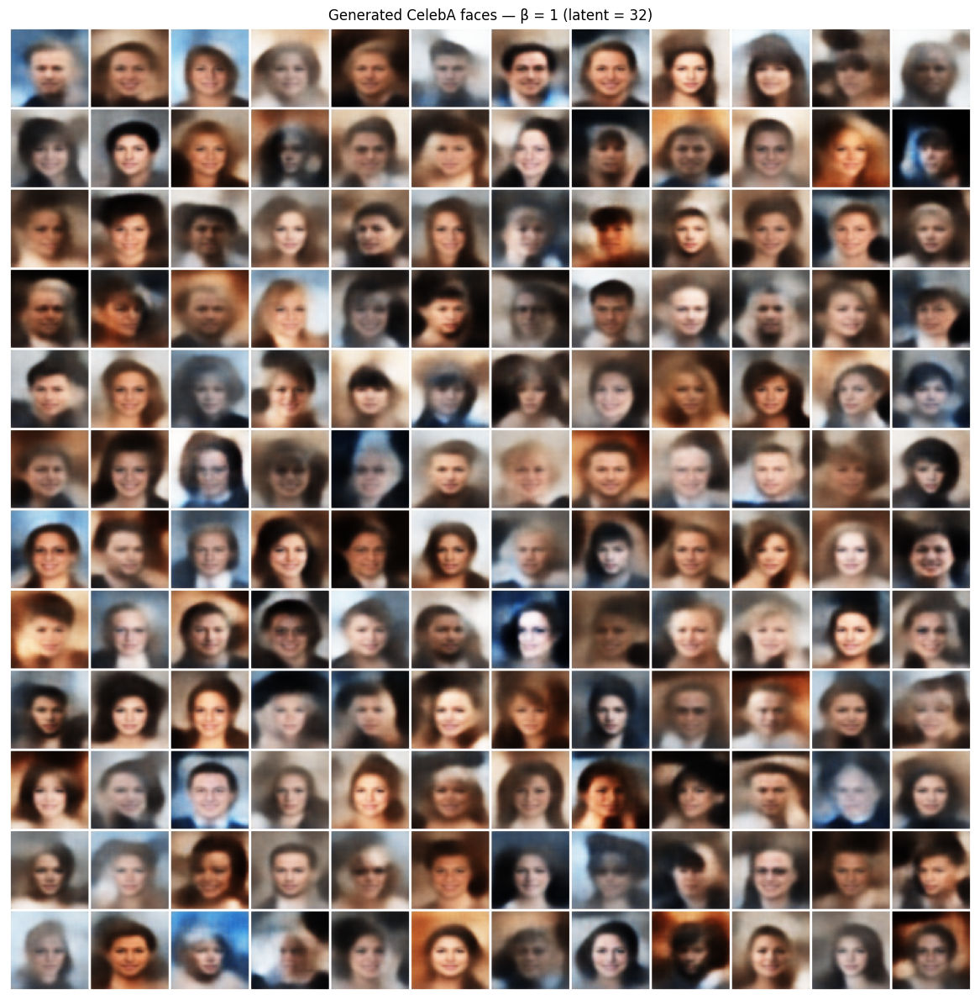

Saved: hw2_figures\b_beta_1p0_decoded_12x12.png
Starting task_b: latent=32, beta=8, epochs=6, train images=162,770
Epoch 1/6
  train: 1696 batches
  train: batch 1/1696 | images 96 | loss 8563.6
  train: batch 200/1696 | images 19,200 | loss 7419.6
  train: batch 400/1696 | images 38,400 | loss 6876.8
  train: batch 600/1696 | images 57,600 | loss 6815.3
  train: batch 800/1696 | images 76,800 | loss 6762.1
  train: batch 1000/1696 | images 96,000 | loss 6671.0
  train: batch 1200/1696 | images 115,200 | loss 6755.1
  train: batch 1400/1696 | images 134,400 | loss 6812.1
  train: batch 1600/1696 | images 153,600 | loss 6516.4
  train: batch 1696/1696 | images 162,770 | loss 6914.1
  validation: 207 batches
  validation: batch 1/207 | images 96 | loss 6681.6
  validation: batch 200/207 | images 19,200 | loss 6748.8
  validation: batch 207/207 | images 19,867 | loss 6820.3
task_b β=8 z=32 epoch 1/6 | train 6910.3 | val 6648.2 | val recon 6428.4 | val KL 27.48 | elapsed 2.0 min
Epoch 2/6


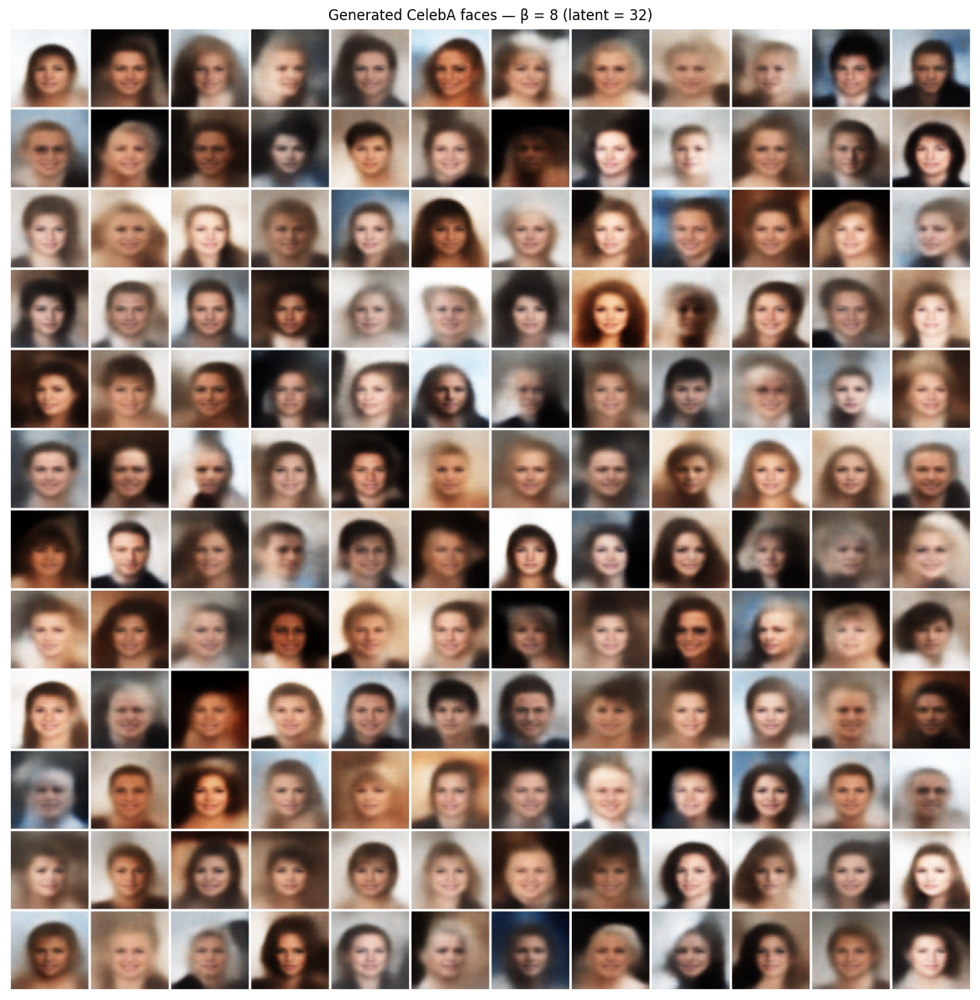

Saved: hw2_figures\b_beta_8p0_decoded_12x12.png


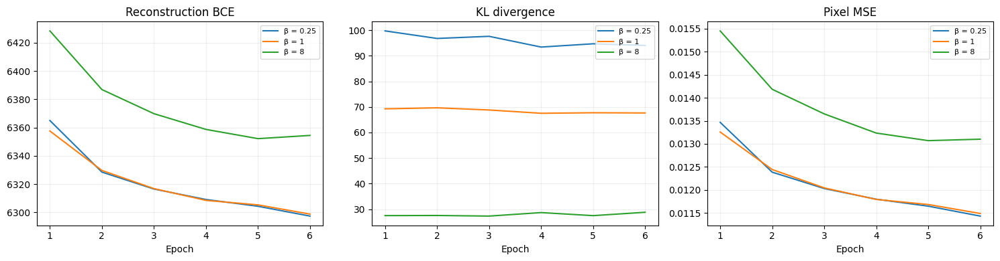

Saved: hw2_figures\b_beta_comparison_training_curves.png

TEST RESULTS (same test images for every model)
    Beta     Recon BCE           KL    Pixel MSE
    0.25       6242.88        94.26     0.011476
       1       6244.19        67.81     0.011527
       8       6300.12        28.93     0.013147


In [9]:
LATENT_LARGE = 32
BETAS = (0.25, 1.0, 8.0)
beta_models = {}
beta_histories = {}
beta_metrics = {}

for beta in BETAS:
    model, history = fit_or_load(latent_dim=LATENT_LARGE, beta=beta,
                                 epochs=EPOCHS_BETA, tag='task_b')
    beta_models[beta] = model
    beta_histories[f'β = {beta:g}'] = history
    beta_metrics[beta] = test_metrics(model, beta)
    generated = decode_fixed_samples(model, LATENT_LARGE, n=144)
    save_grid(generated,
              f'b_beta_{str(beta).replace(".", "p")}_decoded_12x12.png',
              f'Generated CelebA faces — β = {beta:g} (latent = 32)')

plot_history(beta_histories, 'b_beta_comparison_training_curves.png')

print('\nTEST RESULTS (same test images for every model)')
print(f'{"Beta":>8} {"Recon BCE":>13} {"KL":>12} {"Pixel MSE":>12}')
for beta, m in beta_metrics.items():
    print(f'{beta:>8g} {m["reconstruction"]:>13.2f} {m["kl"]:>12.2f} {m["pixel_mse"]:>12.6f}')

β = 0.25: varying latent dimensions [23, 14]


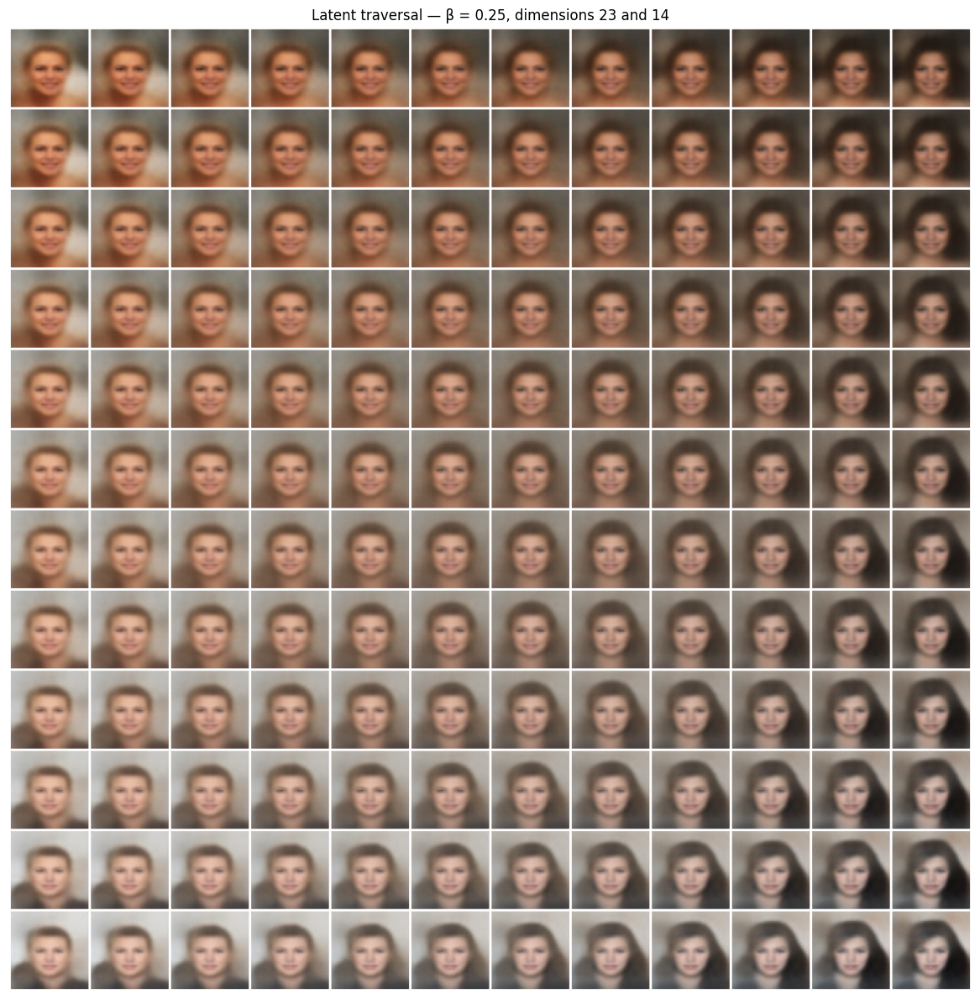

Saved: hw2_figures\b_beta_0p25_traversal_12x12.png
β = 1: varying latent dimensions [18, 1]


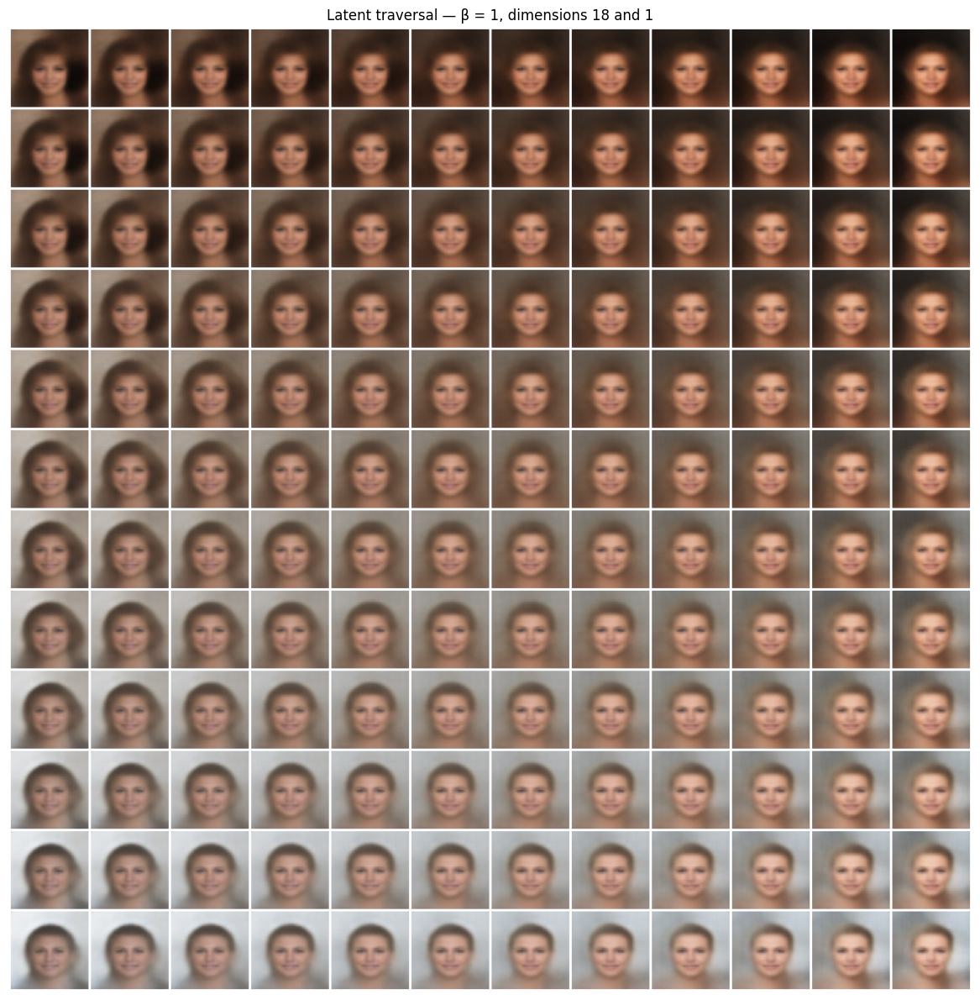

Saved: hw2_figures\b_beta_1p0_traversal_12x12.png
β = 8: varying latent dimensions [27, 29]


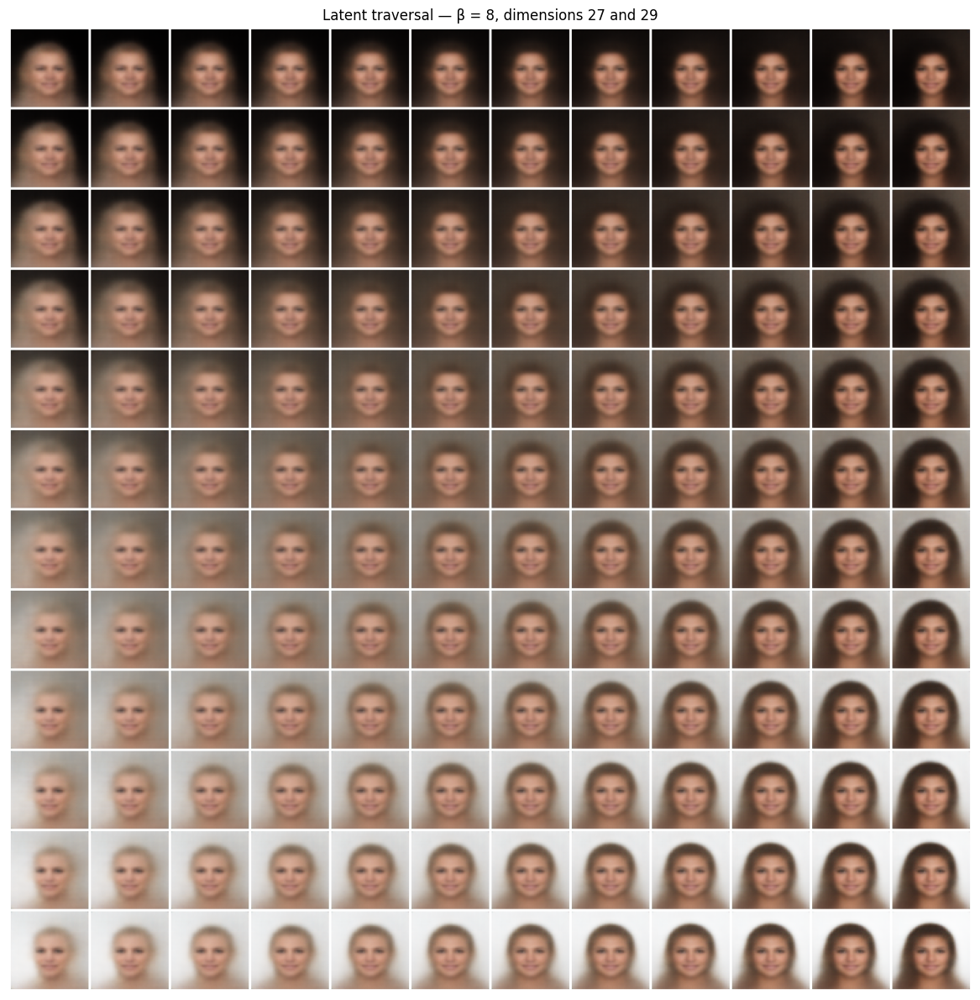

Saved: hw2_figures\b_beta_8p0_traversal_12x12.png


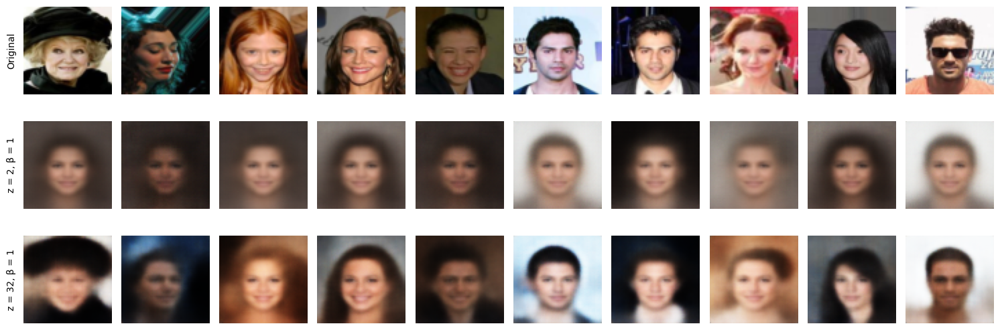

Saved: hw2_figures\a_z2_vs_z32_first_10.png
Same-β reconstruction comparison on the test set:
z = 2,  β = 1 | Pixel MSE: 0.04069
z = 32, β = 1 | Pixel MSE: 0.011527


In [10]:
@torch.no_grad()
def latent_traversal(model, latent_dim, n=12, n_reference=512):
    model.eval()
    # Identify coordinates showing the most variation in the encoded means.
    batches = []
    n_reference = min(n_reference, len(valset))
    for first in range(0, n_reference, 64):
        x = torch.stack([valset[i] for i in range(first, min(first+64, n_reference))]).to(DEVICE)
        mean, _ = model.encoder(x)
        batches.append(mean.cpu())
    means = torch.cat(batches)
    dims = torch.argsort(means.var(0), descending=True)[:2].tolist()
    anchor = means.mean(0)
    span = torch.linspace(-2, 2, n)
    mesh = torch.stack(torch.meshgrid(span, span, indexing='ij'), -1).reshape(-1, 2)
    z = anchor.repeat(n*n, 1)
    z[:, dims[0]] = mesh[:, 0]
    z[:, dims[1]] = mesh[:, 1]
    out = model.generate(z.to(DEVICE)).cpu()
    return out, dims

for beta, model in beta_models.items():
    traversal, dims = latent_traversal(model, LATENT_LARGE)
    print(f'β = {beta:g}: varying latent dimensions {dims}')
    save_grid(traversal,
              f'b_beta_{str(beta).replace(".", "p")}_traversal_12x12.png',
              f'Latent traversal — β = {beta:g}, dimensions {dims[0]} and {dims[1]}')

# Directly compare reconstruction of the same 10 images for beta=1, z=2 vs z=32.
recon_32 = reconstruct_first_ten(beta_models[1.0])
save_reconstruction_comparison(fixed_test, [recon_2d, recon_32],
                               ['z = 2, β = 1', 'z = 32, β = 1'],
                               'a_z2_vs_z32_first_10.png')

print('Same-β reconstruction comparison on the test set:')
print('z = 2,  β = 1 | Pixel MSE:', round(metrics_2d['pixel_mse'], 6))
print('z = 32, β = 1 | Pixel MSE:', round(beta_metrics[1.0]['pixel_mse'], 6))

### Analysis — Question 1(b)

I trained three β-VAE models using β = 0.25, β = 1 and β = 8, with a latent dimension of 32. I wanted to see how changing β affects the quality and variation of the generated faces. Looking at the 12×12 image grids, I noticed that the models produced different results even though they were trained on the same dataset.

With β = 0.25, the generated faces showed more variation in hairstyles, colours and backgrounds. However, some of the faces were not very clear. When β = 1, the faces still showed different features, with a reasonable balance between image quality and variation. With β = 8, the generated faces appeared more similar to each other and some details became less noticeable.

The numerical results also show these differences. The model with β = 0.25 achieved the lowest test pixel MSE of **0.011476**, followed by β = 1 with **0.011527** and β = 8 with **0.013147**. The KL divergence decreased from **94.26** at β = 0.25 to **67.81** at β = 1 and **28.93** at β = 8. This shows that increasing β made the model keep its latent distribution closer to the standard normal distribution, but it also reduced the amount of detail it could preserve.

From the latent traversal grids, I observed that changing the latent values produced gradual changes in facial appearance. However, several facial features sometimes changed together, so I could not clearly identify one latent dimension controlling only one feature.

Overall, I found that β = 0.25 gave the lowest reconstruction error, while β = 8 applied stronger regularization. The experiment shows that increasing β does not automatically improve the generated images. A balance is needed between reconstruction quality and learning a well-organized latent space.

## Question 1(c) — Excessive regularization with a stronger β (30 points)

I use **β = 100**, which is much larger than the highest value in Task 1(b). This increases the penalty on KL divergence. If the model puts nearly every image close to the prior, different inputs can decode to similar, generic-looking faces. To show the difference, I display **ten generated faces** using random latent vectors, and I separately compare the first ten real test images against their reconstructions. The second comparison makes it easier to judge reconstruction quality, which is the main issue in this question.

Starting task_c: latent=32, beta=100, epochs=5, train images=162,770
Epoch 1/5
  train: 1696 batches
  train: batch 1/1696 | images 96 | loss 8601.2
  train: batch 200/1696 | images 19,200 | loss 7761.9
  train: batch 400/1696 | images 38,400 | loss 7650.6
  train: batch 600/1696 | images 57,600 | loss 7410.2
  train: batch 800/1696 | images 76,800 | loss 7653.5
  train: batch 1000/1696 | images 96,000 | loss 7436.3
  train: batch 1200/1696 | images 115,200 | loss 7551.0
  train: batch 1400/1696 | images 134,400 | loss 7439.2
  train: batch 1600/1696 | images 153,600 | loss 7336.8
  train: batch 1696/1696 | images 162,770 | loss 7595.3
  validation: 207 batches
  validation: batch 1/207 | images 96 | loss 7347.4
  validation: batch 200/207 | images 19,200 | loss 7477.7
  validation: batch 207/207 | images 19,867 | loss 7462.7
task_c β=100 z=32 epoch 1/5 | train 7601.4 | val 7337.4 | val recon 7003.2 | val KL 3.34 | elapsed 2.0 min
Epoch 2/5
  train: 1696 batches
  train: batch 1/1696 |

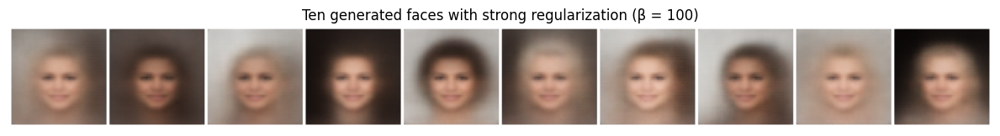

Saved: hw2_figures\c_beta100_generated_10.png


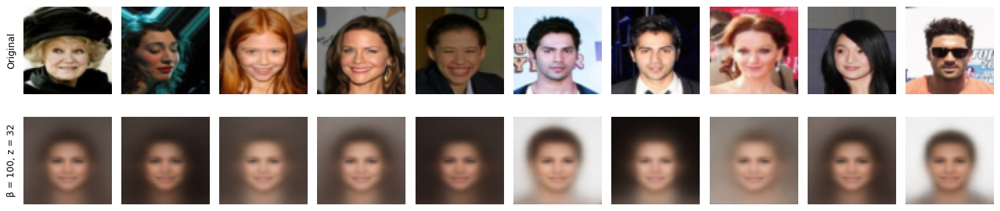

Saved: hw2_figures\c_beta100_reconstructions_10.png


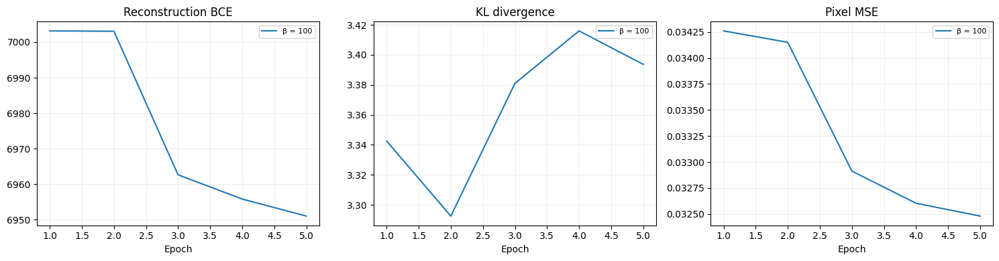

Saved: hw2_figures\c_beta100_training_curves.png
Comparison of the regularized models (test set):
β=1: reconstruction BCE 6244.19, KL 67.81, pixel MSE 0.011527
β=8: reconstruction BCE 6300.12, KL 28.93, pixel MSE 0.013147
β=100: reconstruction BCE 6907.53, KL 3.39, pixel MSE 0.032823


In [11]:
STRONG_BETA = 100.0
strong_model, strong_history = fit_or_load(latent_dim=LATENT_LARGE,
                                          beta=STRONG_BETA,
                                          epochs=EPOCHS_STRONG, tag='task_c')
strong_metrics = test_metrics(strong_model, STRONG_BETA)
strong_generated = decode_fixed_samples(strong_model, LATENT_LARGE, n=10)
save_grid(strong_generated, 'c_beta100_generated_10.png',
          'Ten generated faces with strong regularization (β = 100)', columns=10)
strong_recon = reconstruct_first_ten(strong_model)
save_reconstruction_comparison(fixed_test, [strong_recon],
                               ['β = 100, z = 32'], 'c_beta100_reconstructions_10.png')
plot_history({'β = 100': strong_history}, 'c_beta100_training_curves.png')

print('Comparison of the regularized models (test set):')
for beta in (1.0, 8.0):
    m = beta_metrics[beta]
    print(f'β={beta:g}: reconstruction BCE {m["reconstruction"]:.2f}, '
          f'KL {m["kl"]:.2f}, pixel MSE {m["pixel_mse"]:.6f}')
print(f'β=100: reconstruction BCE {strong_metrics["reconstruction"]:.2f}, '
      f'KL {strong_metrics["kl"]:.2f}, pixel MSE {strong_metrics["pixel_mse"]:.6f}')

### Analysis — Question 1(c)

For this experiment, I increased β to **100** to observe what happens when the regularization becomes too strong. After training the model, I generated ten face images and compared the reconstruction results with those from the models using smaller β values.

Looking at the generated images, I noticed that most of the faces appeared very similar. There was less variation in facial features, hairstyles and expressions. The reconstructed faces were also blurrier, and the model struggled to preserve differences between the original images. Instead of reconstructing each person's appearance clearly, it produced faces with similar general features.

The numerical results confirm this observation. With β = 100, the test pixel MSE increased to **0.032823**, compared with **0.011527** at β = 1 and **0.013147** at β = 8. At the same time, the KL divergence decreased significantly to **3.39**, compared with **67.81** at β = 1 and **28.93** at β = 8.

This happened because the high β value placed too much importance on keeping the latent distribution close to the standard normal distribution. As a result, the encoder could not preserve enough information about individual faces, which caused the reconstructions to lose detail.

Based on these results, I concluded that **β = 100 caused excessive regularization** in my model. Although the KL divergence became much smaller, the reconstruction quality and variation of the generated faces became worse. This shows that stronger regularization is not always better, because the model still needs enough information in its latent space to reconstruct meaningful images.

## Final checks

I saved each figure as a PNG file and kept model checkpoints separate from the notebook. All three questions share the same image preprocessing. Question 1(a) uses the first ten test images, Question 1(b) includes four required 12×12 grids (the original images and one generated grid for each β value), and Question 1(c) includes ten generated images plus reconstruction comparisons.

Before uploading, I will confirm that the notebook was run from top to bottom with **`SMOKE_TEST = False`**, review the saved figures to make sure the images show the requested differences, and save the completed notebook under my student ID.

In [ ]:
required_files = [
    'original_12x12.png',
    'a_first_10_reconstructions.png',
    'a_z2_vs_z32_first_10.png',
    'b_beta_0p25_decoded_12x12.png',
    'b_beta_1p0_decoded_12x12.png',
    'b_beta_8p0_decoded_12x12.png',
    'c_beta100_generated_10.png',
    'c_beta100_reconstructions_10.png',
]
missing = [name for name in required_files if not (FIG_DIR / name).is_file()]
print('Saved PNG figures:', len(list(FIG_DIR.glob('*.png'))))
print('Required files missing:', missing if missing else 'None')
if missing:
    raise RuntimeError('One or more figures were not saved. Run the cells above first.')
if SMOKE_TEST:
    raise RuntimeError('SMOKE_TEST=True. Run again with SMOKE_TEST=False before submitting.')
print('All figure checks passed. Save this notebook with Ctrl+S.')

Saved PNG figures: 14
Required files missing: None
All figure checks passed. Save this notebook with Ctrl+S.
